#### Forward kinematics of `ROBOTIS FFW SG2`
- `sg2`: `s`werve drive with `g`ripper `2`fingers

In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.mujoco_sim import *
from package.kinematics import *
from package.utility import *
from package.qt import *
from PyQt5.QtWidgets import QApplication
app = QApplication(sys.argv)

[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files=[
        "../asset/floor/floor_simple_white.xml",
        "../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml",
    ],
    output_xml_path = "xml/scene_ffw_sg2.xml",
)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)

[merge_mjcfs] Merging [2] MJCF files:
  - [0] [../asset/floor/floor_simple_white.xml]
  - [1] [../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml]
[merge_mjcfs] Saved merged XML to:[xml/scene_ffw_sg2.xml]
MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


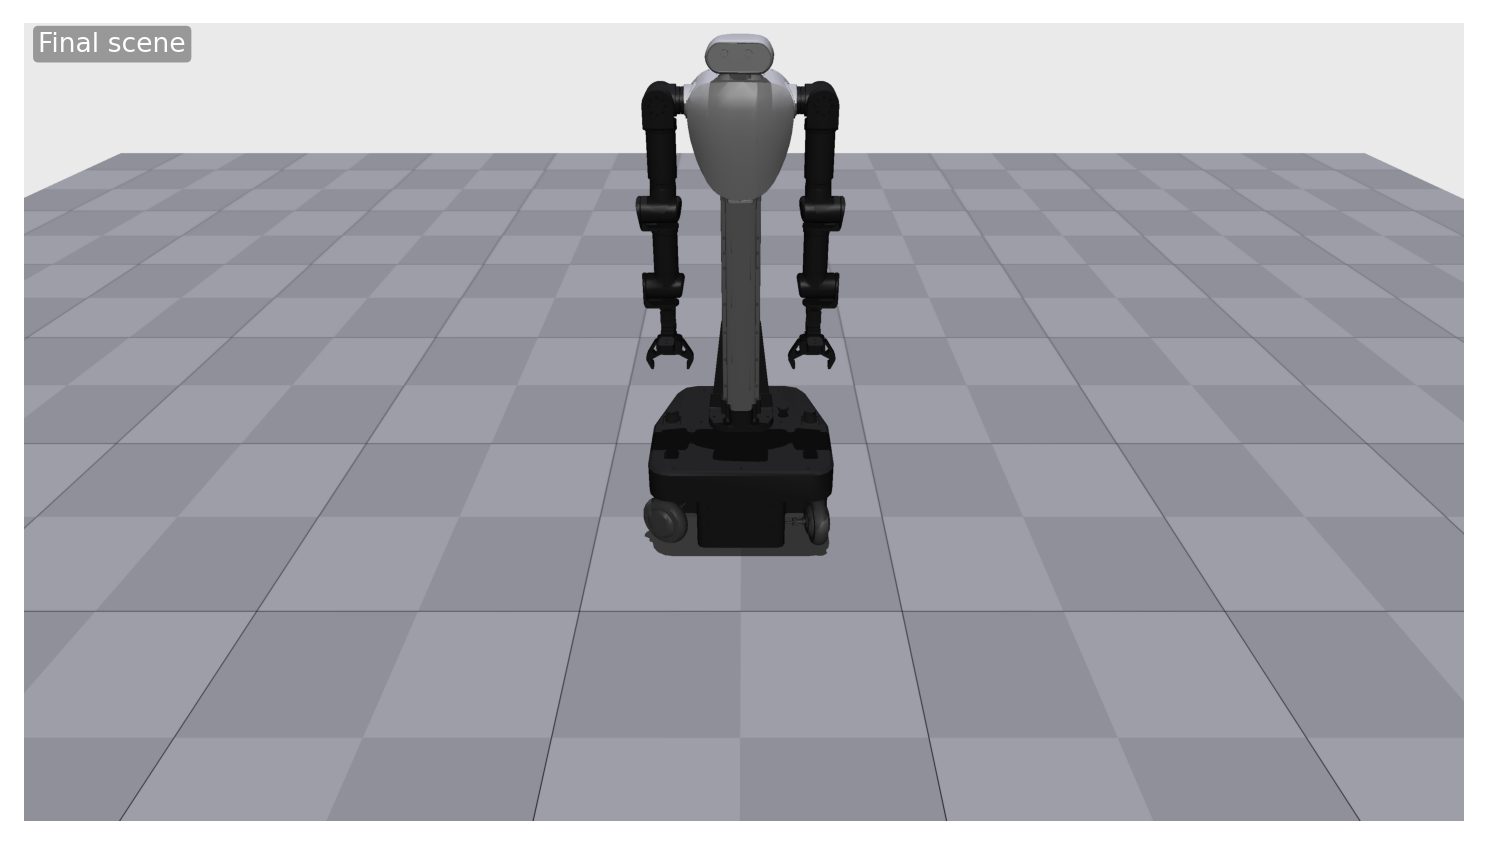

Done.


In [3]:
# Reset
env.reset()
env.init_viewer(title="FFW SG2", width=1.0, height=1.0, fontscale=200)
env.viewer.set_cam_info(180, 3.2, -30, [0.02, 0.01, 0.4])
env.viewer.set_transparency(transparent=False)
env.viewer.set_geomgroup(group_2=True, group_3=False)

# Sliders (active joints)
sliders = MultiSliderQtWidget(
    window_width  = 0.2,
    window_height = 1.0,
    label_texts   = env.rev_pri_joint_names,
    label_colors  = get_label_colors_from_joint_axis(env,env.rev_pri_joint_names),
    slider_vals   = env.get_qpos(joint_names=env.rev_pri_joint_names),
    slider_mins   = env.rev_pri_joint_mins,
    slider_maxs   = env.rev_pri_joint_maxs,
    fontsize      = 30,
)

# Loop
idxs_rev_pri2active = get_idxs(env.rev_pri_joint_names,env.active_joint_names)
idxs_rev_pri2rev    = get_idxs(env.rev_pri_joint_names,env.rev_joint_names)
while env.is_viewer_alive():
    app.processEvents()
    # Sliders
    q_rev_pri = sliders.get_values() # get revolute + prismatic
    q_active = q_rev_pri[idxs_rev_pri2active] # get active part
    q_rev = env.get_qrev_from_qactive(q_active) # recon revolute from active 
    q_rev_pri[idxs_rev_pri2rev] = q_rev # override revolute
    sliders.set_values(q_rev_pri) # modify revolute parts of the sliders

    # Update
    env.forward(q=q_rev_pri,joint_names=env.rev_pri_joint_names)
    
    # Render
    env.plot_time()
    env.plot_global_coordinate_axes()
    env.plot_contact_info()
    env.plot_sites(show_names=True)
    env.plot_links_between_bodies()
    env.plot_rev_joint_axis(rate=0.5)
    env.render()

# Plot final scene
imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)

# Close
env.close_viewer()
sliders.close()
print("Done.")